# 06 — Market Regime

Rule-based first. HMM/ML can be added later.


In [1]:
# Cell: Setup Project Root
import os
import sys
from pathlib import Path


def find_project_root(start_path=None):
    path = Path(start_path or os.getcwd()).resolve()
    for parent in [path, *path.parents]:
        if (parent / "src").is_dir() and (parent / "config").is_dir():
            return parent
    raise FileNotFoundError("Khong tim thay project root co thu muc src/ va config/")


project_root = find_project_root()
os.chdir(project_root)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)


Project root: /Users/jamesb/Desktop/vietnam-quant-research


In [2]:
# Cell: Import Market Regime Modules
import importlib

from src.analytics.entropy import build_market_entropy_profile
from src.data.loaders import read_parquet, save_parquet
from src.features.breadth import calculate_market_breadth
from src.models.regime import add_market_regime
from src.reporting.chart_factory import entropy_regime_chart


In [3]:
# Cell: Build Market Regime Frame
features = read_parquet("data/processed/stock_features.parquet")
features["date"] = features["date"].astype("datetime64[ns]")

# NV1 fix (docs/reports/codebase_audit/MARKET_REGIME_AUDIT.md): add_market_regime
# needs the real VNINDEX benchmark, or it silently falls back to its pre-fix
# backward-compatible mode (index_above_ma50/200 always False, "Risk-on"
# structurally unreachable -- see add_index_trend_features's docstring in
# src/models/regime.py). scripts/generate_features.py already does this
# correctly (Step 5); this notebook previously did not.
benchmark = read_parquet("data/processed/benchmark_vnindex.parquet")

breadth = calculate_market_breadth(features)
market = add_market_regime(breadth, benchmark=benchmark)
market_entropy = build_market_entropy_profile(features, windows=[21, 63, 126], n_bins=24)
market = market.merge(market_entropy, on="date", how="left")
market.shape


(1634, 24)

In [4]:
# Cell: Inspect Market Regime Outputs
display(market.tail(20))
latest_market = market.sort_values("date").tail(1)
display(latest_market[[col for col in ["date", "market_regime", "market_entropy_21d", "market_entropy_63d", "market_entropy_regime", "market_entropy_shift", "advance_ratio"] if col in latest_market.columns]])
display(entropy_regime_chart(market, entropy_col="market_entropy_21d", regime_col="market_entropy_regime", title="VN Market Entropy Profile (21D)"))

print(
    "Luu y ve market_entropy_regime (NV3, docs/reports/codebase_audit/MARKET_REGIME_AUDIT.md): "
    "nguong Structured/Chaotic da duoc HIEU CHINH LAI theo phan vi thuc te "
    "(15th/85th percentile cua market_entropy_21d, toan bo lich su that "
    "2020-01 -> 2026-07) thay cho hang so cu 0.35/0.70 khong ro nguon goc "
    "(nguong cu chua bao gio phan loai duoc 'Structured' trong 6.5 nam du "
    "lieu that -- xem src/analytics/entropy.py). Day la mot phep HIEU CHINH "
    "XAC DINH tu phan phoi du lieu, KHONG PHAI kiem dinh kha nang du bao -- "
    "entropy_regime van CHUA duoc test IC/backtest o bat ky dau trong du an. "
    "Khong dung lam tin hieu giao dich cho den khi co prereg rieng."
)


,date,stock_count,pct_above_ma20,pct_above_ma50,pct_above_ma200,advance_count,decline_count,advance_decline_ratio,up_down_volume_ratio,index_drawdown_pct,...,market_regime,crash_severity,breakout_signal,market_proxy_return_1d,advance_ratio,market_entropy_21d,market_entropy_63d,market_entropy_126d,market_entropy_regime,market_entropy_shift
1614,2026-06-25,434,0.359447,0.281106,0.262673,145,210,0.690476,0.641554,-0.033647,...,Neutral,Normal,Normal,-0.000430,0.334101,0.791809,0.723364,0.622918,Transitional,Stable
1615,2026-06-26,442,0.371041,0.307692,0.285068,140,229,0.611354,1.375932,-0.029062,...,Neutral,Normal,Normal,-0.001796,0.316742,0.754319,0.723364,0.622691,Transitional,Stable
1616,2026-06-29,446,0.428251,0.325112,0.291480,217,154,1.409091,2.704429,-0.037849,...,Neutral,Normal,Normal,0.002368,0.486547,0.771037,0.706628,0.622918,Transitional,Stable
1617,2026-06-30,438,0.442922,0.342466,0.301370,171,173,0.988439,1.247578,-0.035234,...,Neutral,Normal,Normal,0.001069,0.390411,0.750265,0.703893,0.617345,Transitional,Stable
1618,2026-07-01,441,0.482993,0.376417,0.301587,220,144,1.527778,5.433053,-0.031500,...,Neutral,Normal,Normal,0.003697,0.498866,0.750265,0.703893,0.615862,Transitional,Stable
1619,2026-07-02,431,0.475638,0.361949,0.310905,146,190,0.768421,0.515793,-0.031946,...,Neutral,Normal,Normal,0.000119,0.338747,0.771037,0.702211,0.615862,Transitional,Stable
1620,2026-07-03,436,0.426606,0.362385,0.305046,135,226,0.597345,0.893525,-0.034161,...,Neutral,Normal,Normal,-0.000883,0.309633,0.776128,0.699027,0.614166,Transitional,Stable
1621,2026-07-06,439,0.353075,0.314351,0.268793,64,312,0.205128,0.157946,-0.043798,...,Risk-off,Normal,Normal,-0.012314,0.145786,0.734585,0.719383,0.618047,Transitional,Stable
1622,2026-07-07,432,0.351852,0.317130,0.275463,186,175,1.062857,4.678610,-0.041334,...,Risk-off,Normal,Normal,0.003039,0.430556,0.713813,0.702191,0.614825,Transitional,Stable
1623,2026-07-08,441,0.369615,0.344671,0.297052,205,145,1.413793,2.699997,-0.038507,...,Neutral,Normal,Normal,0.002902,0.464853,0.713813,0.702191,0.614825,Transitional,Stable


,date,market_regime,market_entropy_21d,market_entropy_63d,market_entropy_regime,market_entropy_shift,advance_ratio
1633,2026-07-22,Risk-off,0.734585,0.779776,Transitional,Stable,0.2


Luu y ve market_entropy_regime (NV3, docs/reports/codebase_audit/MARKET_REGIME_AUDIT.md): nguong Structured/Chaotic da duoc HIEU CHINH LAI theo phan vi thuc te (15th/85th percentile cua market_entropy_21d, toan bo lich su that 2020-01 -> 2026-07) thay cho hang so cu 0.35/0.70 khong ro nguon goc (nguong cu chua bao gio phan loai duoc 'Structured' trong 6.5 nam du lieu that -- xem src/analytics/entropy.py). Day la mot phep HIEU CHINH XAC DINH tu phan phoi du lieu, KHONG PHAI kiem dinh kha nang du bao -- entropy_regime van CHUA duoc test IC/backtest o bat ky dau trong du an. Khong dung lam tin hieu giao dich cho den khi co prereg rieng.


In [5]:
# Cell: Save Market Regime Outputs
# GUARDED WRITE (docs/reports/codebase_audit/MARKET_REGIME_AUDIT.md NV1) --
# same pattern as 05_volatility_regime.ipynb's save cell.
from src.data.production_guard import guard_production_write, ProductionWriteBlocked

output_path = "data/processed/market_features.parquet"
try:
    guard_production_write(output_path)
    save_parquet(market, output_path)
    print(f"Da ghi {output_path} (ALLOW_PRODUCTION_WRITE=1).")
except ProductionWriteBlocked as e:
    print(f"KHONG ghi {output_path} -- {e}")

display(market["market_regime"].value_counts(dropna=False))
market["market_entropy_regime"].value_counts(dropna=False) if "market_entropy_regime" in market.columns else None


KHONG ghi data/processed/market_features.parquet -- Refusing to write data/processed/market_features.parquet -- this is a shared production file read by ~20 other scripts/modules (build_portfolio_stack.py, run_alpha_scoring.py, final_watchlist.py, ...). The canonical way to regenerate it is `python scripts/generate_features.py`, not this notebook. If you really mean to overwrite it by hand (e.g. debugging), set ALLOW_PRODUCTION_WRITE=1 before starting the kernel, or pass allow=True to guard_production_write(). See docs/reports/codebase_audit/MARKET_REGIME_AUDIT.md for the incident this guards against.


market_regime
Neutral     857
Risk-off    505
Risk-on     272
Name: count, dtype: int64

market_entropy_regime
Transitional    1155
Structured       230
Chaotic          228
Unknown           21
Name: count, dtype: int64

## Market Regime Visualizations

The following sections plot the market regimes against index drawdown, moving average breadth, return entropy dynamics, and advance/decline breadth.

In [6]:
# Cell: Setup Visualizations and Styles
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Set styling using custom rcParams
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.dpi": 150,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linestyle": ":"
})


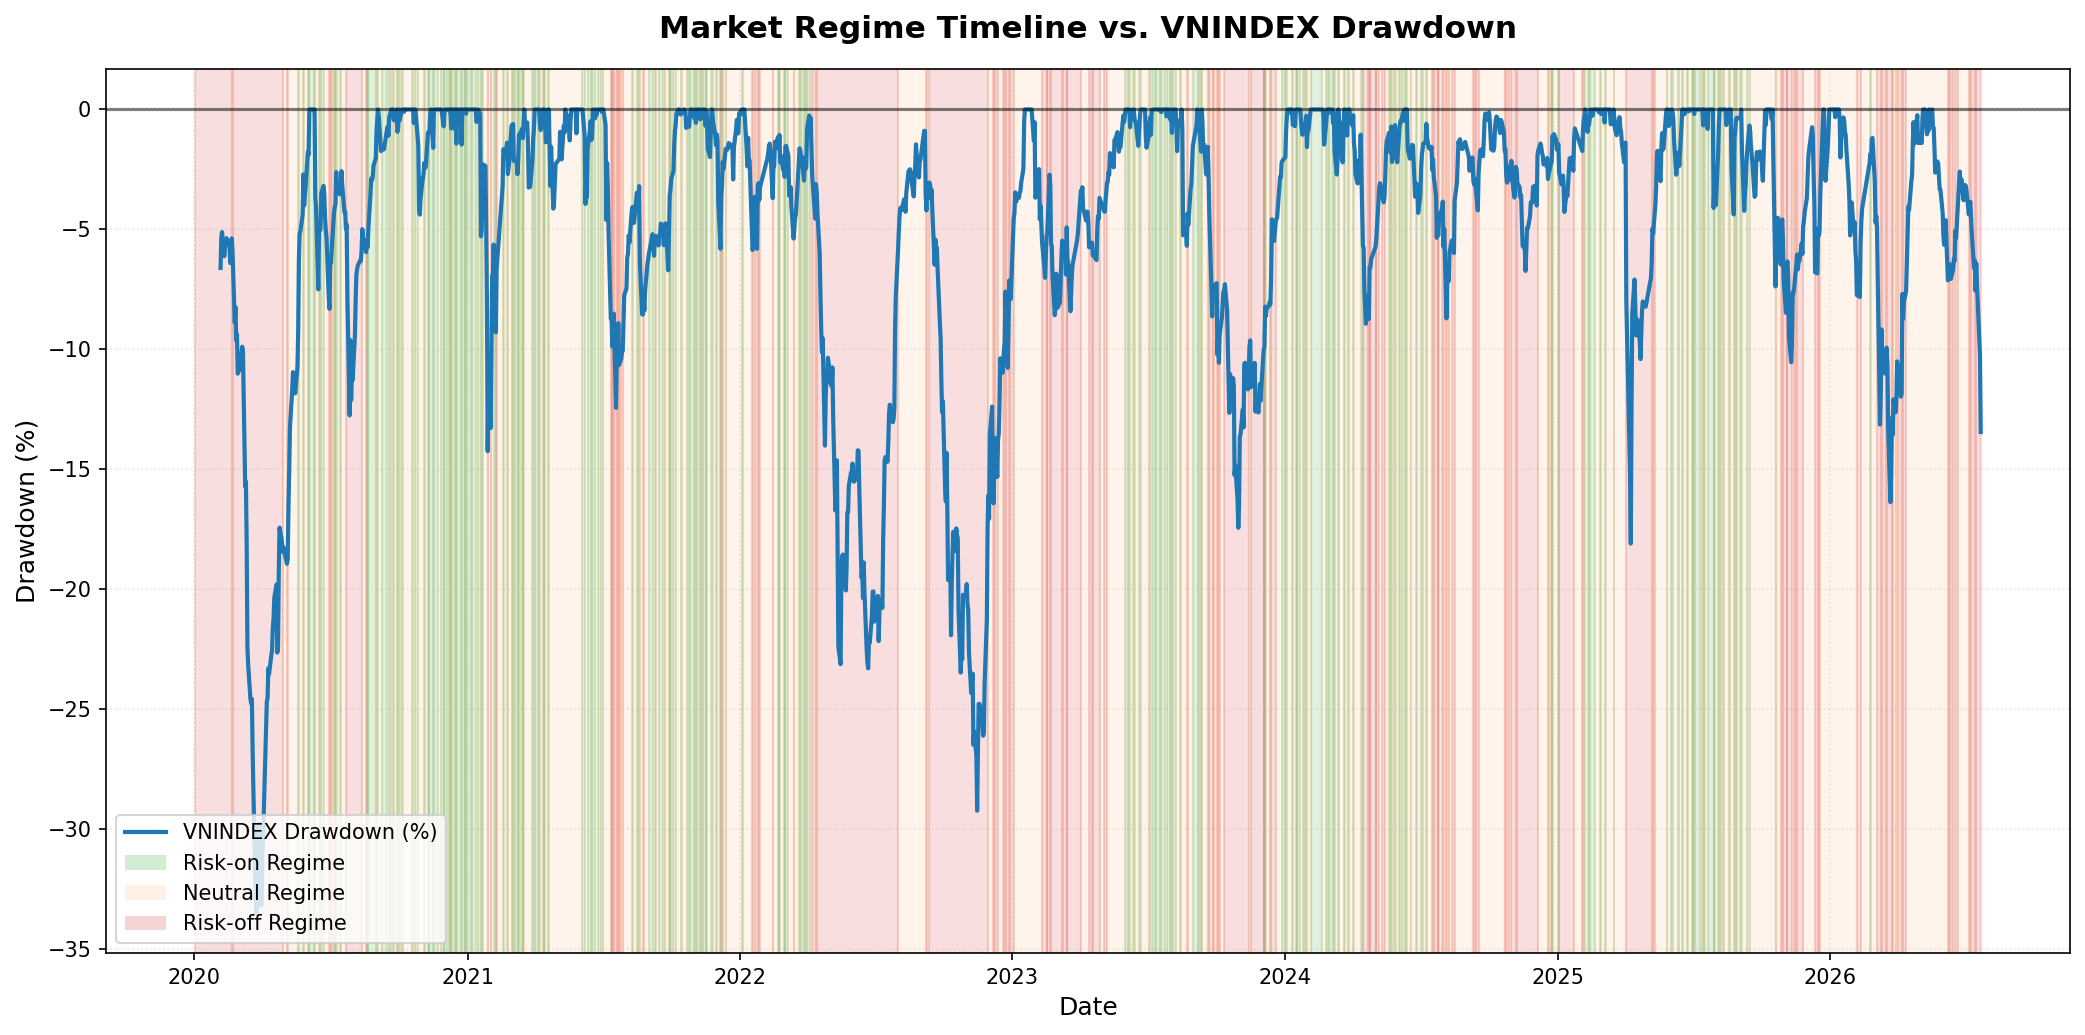

In [7]:
# Cell: Plot 1 - Market Regime Timeline vs. VNINDEX Drawdown
# Convert date to datetime
market["date"] = pd.to_datetime(market["date"])
market_sorted = market.sort_values("date")

fig, ax = plt.subplots(figsize=(14, 7))

# Plot VNINDEX drawdown
ax.plot(market_sorted["date"], market_sorted["index_drawdown_pct"] * 100.0, color="#1f77b4", linewidth=2, label="VNINDEX Drawdown (%)")
ax.axhline(0, color="black", linestyle="-", alpha=0.5)

# Shade background based on market_regime
regimes = market_sorted["market_regime"].values
dates = market_sorted["date"].values

start_idx = 0
for i in range(1, len(market_sorted)):
    if regimes[i] != regimes[start_idx] or i == len(market_sorted) - 1:
        regime = regimes[start_idx]
        color = "#7f7f7f"  # default gray
        alpha = 0.05
        
        if str(regime).lower() in ["risk-on", "riskon"]:
            color = "#2ca02c"  # green
            alpha = 0.15
        elif str(regime).lower() in ["risk-off", "riskoff"]:
            color = "#d62728"  # red
            alpha = 0.15
        elif str(regime).lower() in ["neutral"]:
            color = "#ff7f0e"  # orange
            alpha = 0.08
            
        ax.axvspan(dates[start_idx], dates[i], color=color, alpha=alpha)
        start_idx = i

# Create custom legend for regimes
legend_elements = [
    Line2D([0], [0], color="#1f77b4", lw=2, label="VNINDEX Drawdown (%)"),
    Patch(facecolor="#2ca02c", edgecolor="none", alpha=0.2, label="Risk-on Regime"),
    Patch(facecolor="#ff7f0e", edgecolor="none", alpha=0.1, label="Neutral Regime"),
    Patch(facecolor="#d62728", edgecolor="none", alpha=0.2, label="Risk-off Regime")
]

ax.set_title("Market Regime Timeline vs. VNINDEX Drawdown", fontsize=15, fontweight="bold", pad=15)
ax.set_xlabel("Date", fontsize=12)
ax.set_ylabel("Drawdown (%)", fontsize=12)
ax.legend(handles=legend_elements, loc="lower left", frameon=True, facecolor="white")

plt.tight_layout()
plt.show()


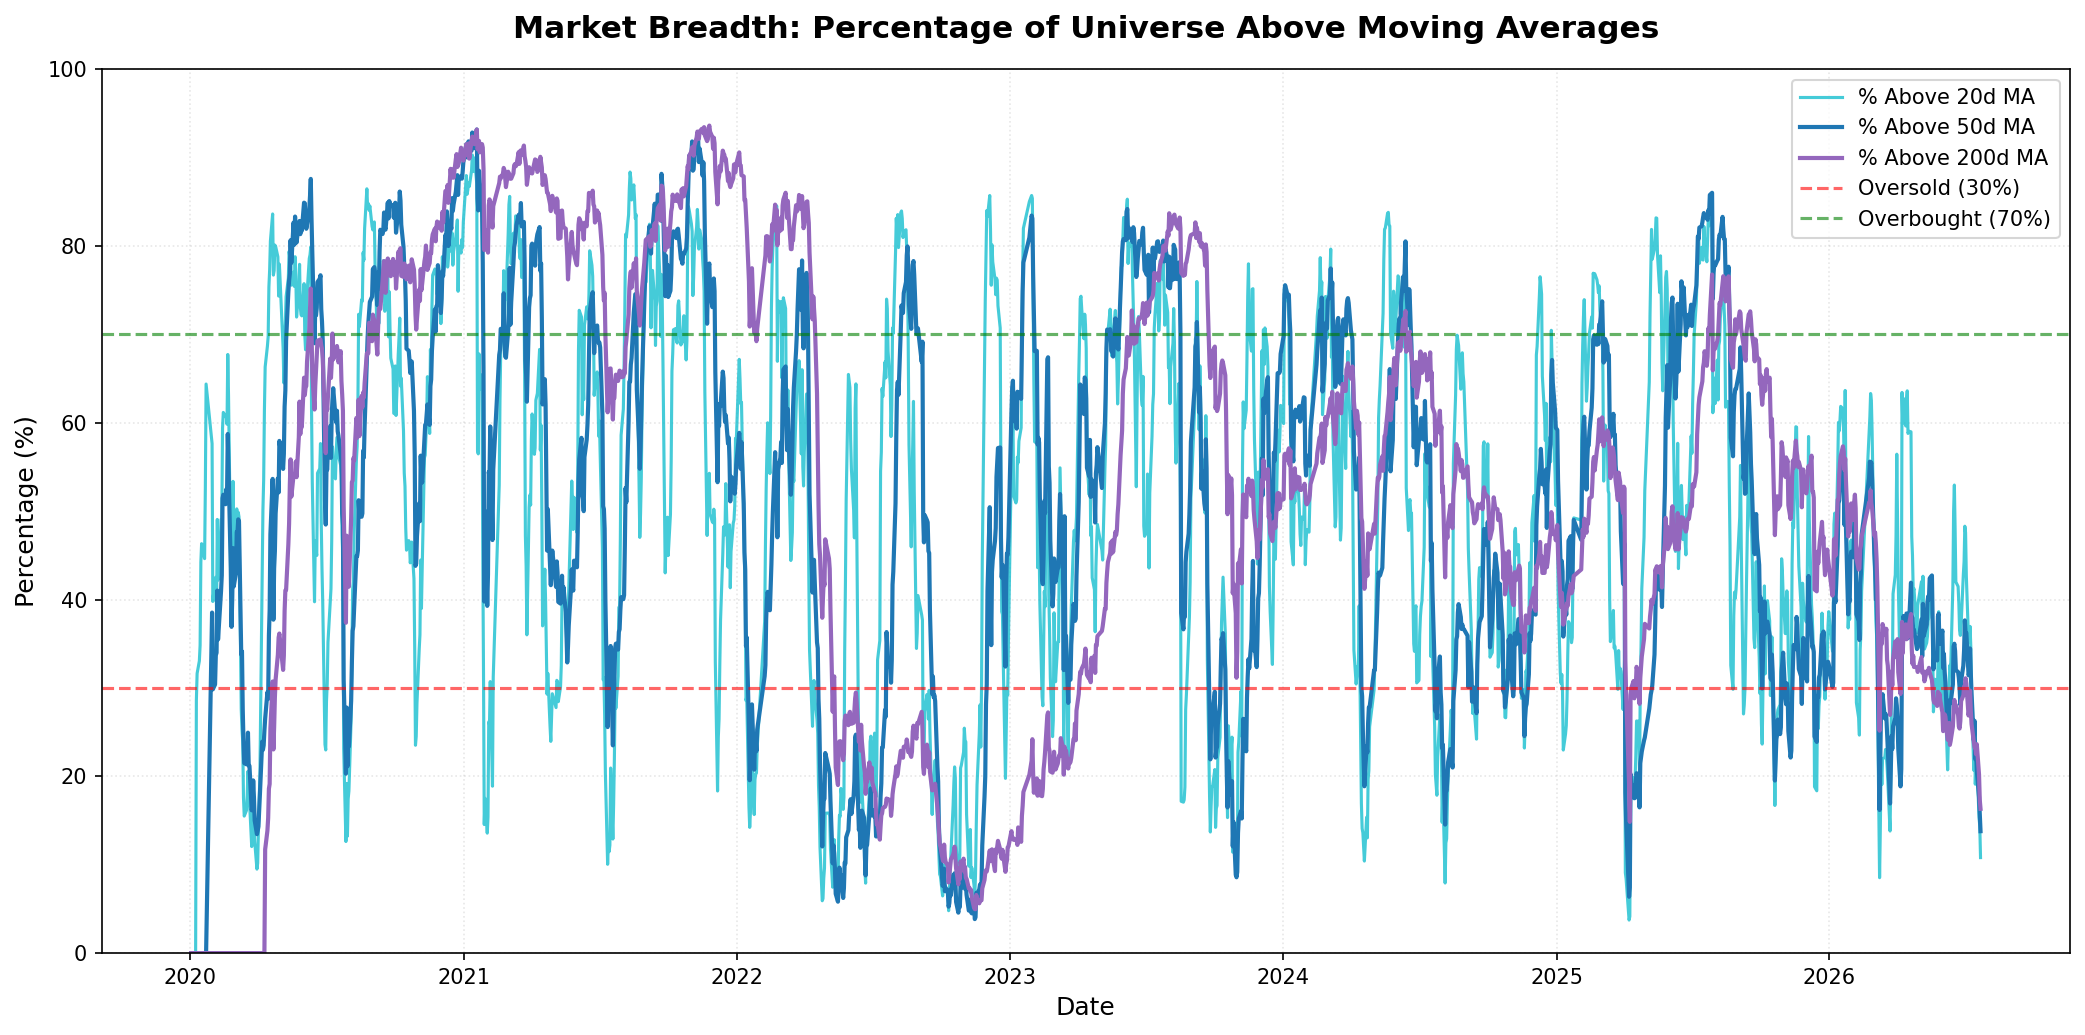

In [8]:
# Cell: Plot 2 - Market Breadth Indicators (Moving Averages)
fig, ax = plt.subplots(figsize=(14, 7))

# Plot Breadth Series
ax.plot(market_sorted["date"], market_sorted["pct_above_ma20"] * 100.0, color="#17becf", linewidth=1.5, alpha=0.8, label="% Above 20d MA")
ax.plot(market_sorted["date"], market_sorted["pct_above_ma50"] * 100.0, color="#1f77b4", linewidth=2.0, label="% Above 50d MA")
ax.plot(market_sorted["date"], market_sorted["pct_above_ma200"] * 100.0, color="#9467bd", linewidth=2.0, label="% Above 200d MA")

# Reference Lines
ax.axhline(30.0, color="red", linestyle="--", alpha=0.6, label="Oversold (30%)")
ax.axhline(70.0, color="green", linestyle="--", alpha=0.6, label="Overbought (70%)")

ax.set_title("Market Breadth: Percentage of Universe Above Moving Averages", fontsize=15, fontweight="bold", pad=15)
ax.set_xlabel("Date", fontsize=12)
ax.set_ylabel("Percentage (%)", fontsize=12)
ax.set_ylim(0, 100)
ax.legend(loc="upper right", frameon=True, facecolor="white")

plt.tight_layout()
plt.show()


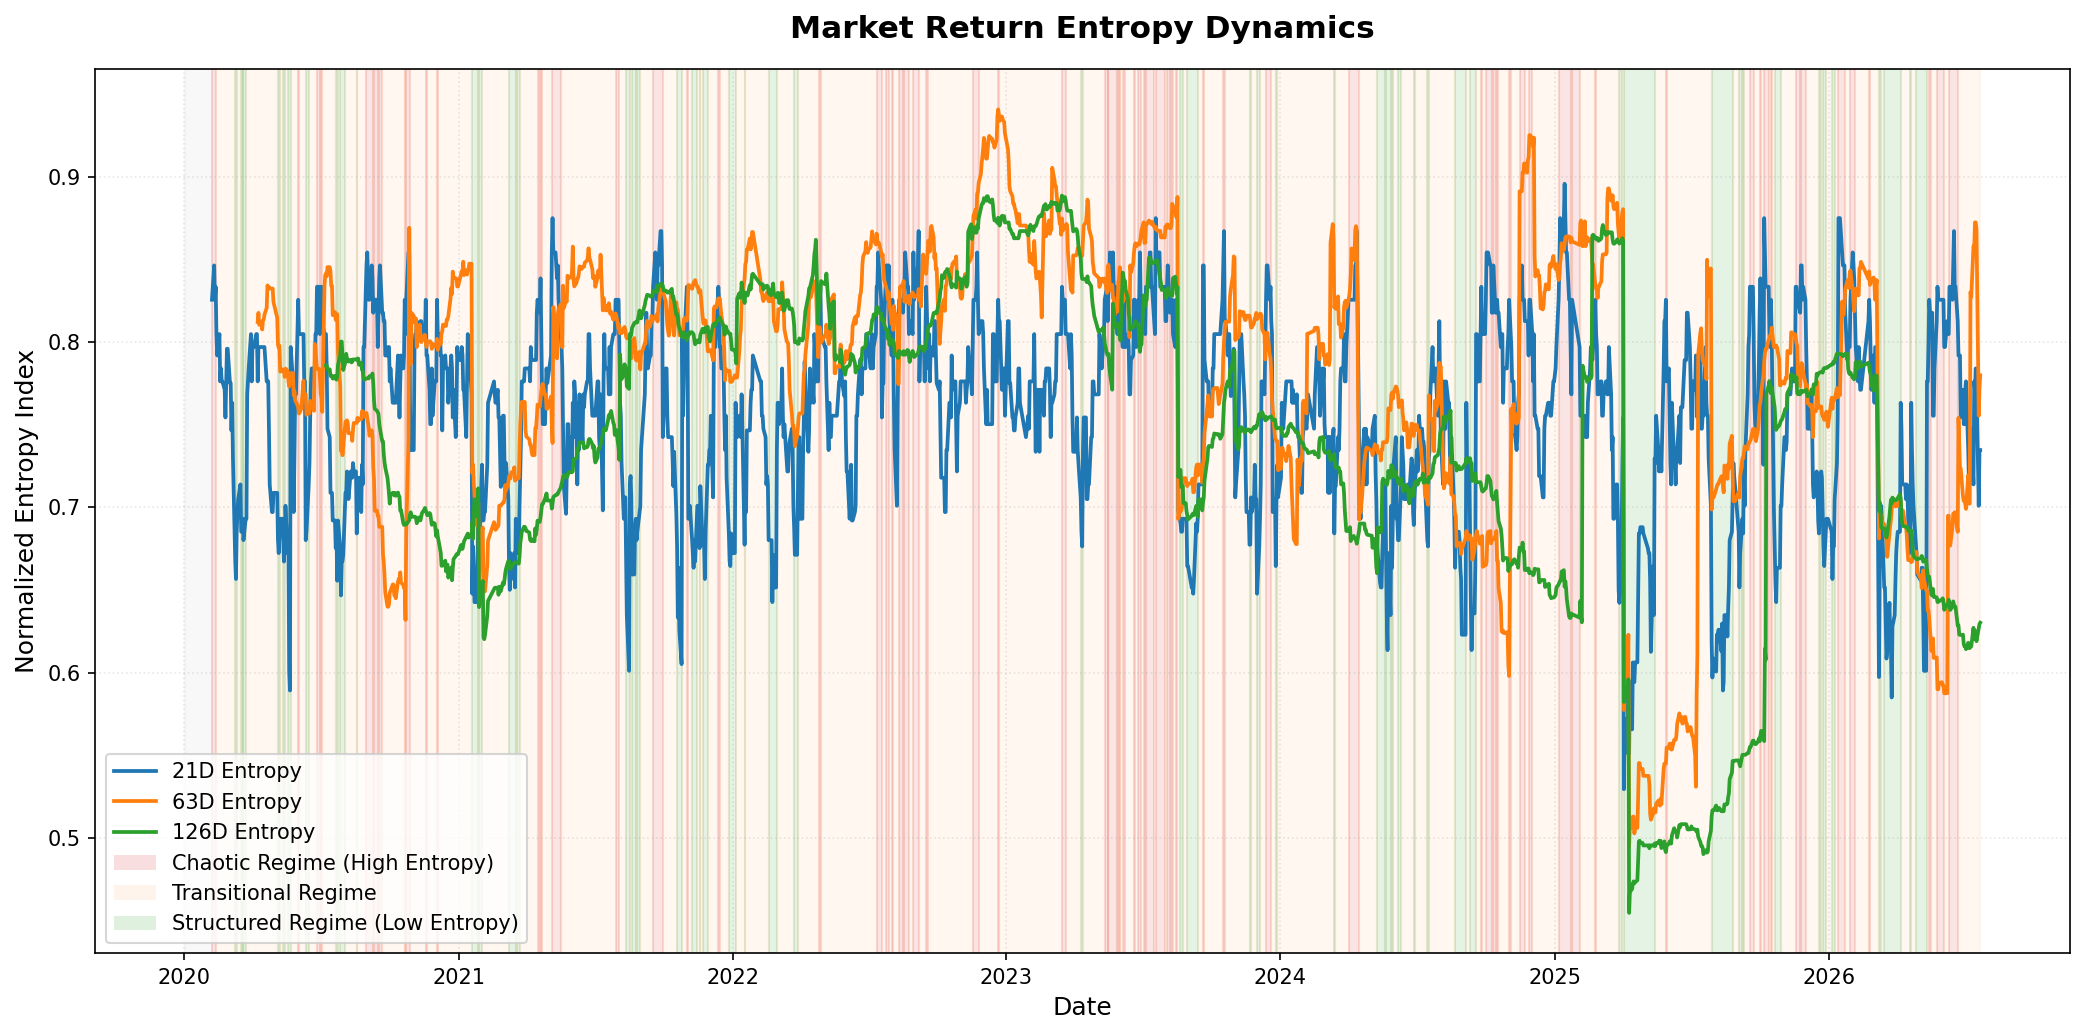

In [9]:
# Cell: Plot 3 - Market Entropy Dynamics and Entropy Regimes
entropy_cols = [c for c in ["market_entropy_21d", "market_entropy_63d", "market_entropy_126d"] if c in market_sorted.columns]

if entropy_cols:
    fig, ax = plt.subplots(figsize=(14, 7))
    
    # Plot Entropy curves
    for col in entropy_cols:
        lbl = col.replace("market_entropy_", "").upper() + " Entropy"
        ax.plot(market_sorted["date"], market_sorted[col], linewidth=1.8, label=lbl)
        
    # Shading based on market_entropy_regime if present
    if "market_entropy_regime" in market_sorted.columns:
        entropy_regimes = market_sorted["market_entropy_regime"].values
        start_idx = 0
        for i in range(1, len(market_sorted)):
            if entropy_regimes[i] != entropy_regimes[start_idx] or i == len(market_sorted) - 1:
                e_regime = entropy_regimes[start_idx]
                color = "#7f7f7f"
                alpha = 0.05
                
                # Shading color based on entropy regime
                if str(e_regime).lower() in ["chaotic"]:
                    color = "#d62728"  # red
                    alpha = 0.12
                elif str(e_regime).lower() in ["structured"]:
                    color = "#2ca02c"  # green
                    alpha = 0.12
                elif str(e_regime).lower() in ["transitional"]:
                    color = "#ff7f0e"  # orange/yellow
                    alpha = 0.06
                    
                ax.axvspan(dates[start_idx], dates[i], color=color, alpha=alpha)
                start_idx = i
                
        # Custom legend for entropy regimes
        legend_patches = [
            Patch(facecolor="#d62728", edgecolor="none", alpha=0.15, label="Chaotic Regime (High Entropy)"),
            Patch(facecolor="#ff7f0e", edgecolor="none", alpha=0.08, label="Transitional Regime"),
            Patch(facecolor="#2ca02c", edgecolor="none", alpha=0.15, label="Structured Regime (Low Entropy)")
        ]
        
        current_handles, current_labels = ax.get_legend_handles_labels()
        ax.legend(handles=current_handles + legend_patches, loc="lower left", frameon=True, facecolor="white")
    else:
        ax.legend(loc="lower left", frameon=True, facecolor="white")
        
    ax.set_title("Market Return Entropy Dynamics", fontsize=15, fontweight="bold", pad=15)
    ax.set_xlabel("Date", fontsize=12)
    ax.set_ylabel("Normalized Entropy Index", fontsize=12)
    
    plt.tight_layout()
    plt.show()
else:
    print("No market entropy columns found for visualization.")


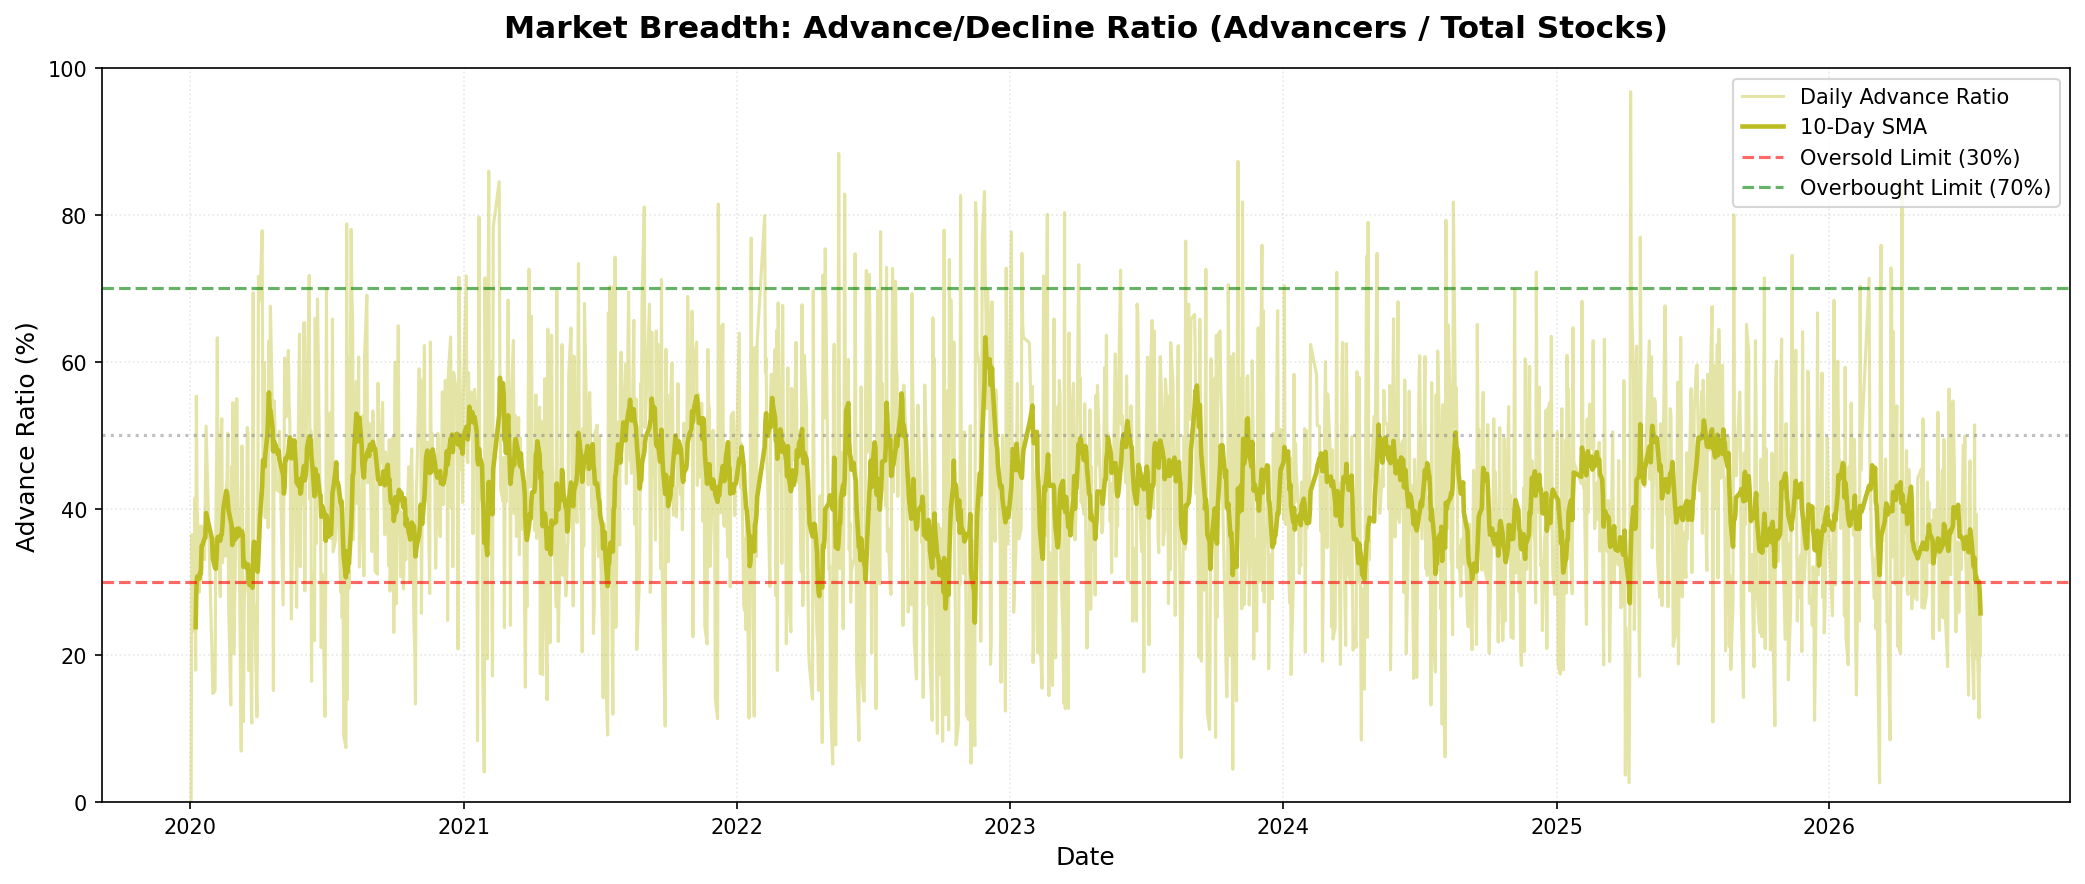

In [10]:
# Cell: Plot 4 - Advance/Decline Breadth (Advance Ratio)
if "advance_ratio" in market_sorted.columns:
    fig, ax = plt.subplots(figsize=(14, 6))
    
    # Calculate a 10-day SMA of the advance ratio
    ma_10d = market_sorted["advance_ratio"].rolling(10, min_periods=5).mean()
    
    ax.plot(market_sorted["date"], market_sorted["advance_ratio"] * 100.0, color="#bcbd22", alpha=0.4, label="Daily Advance Ratio")
    ax.plot(market_sorted["date"], ma_10d * 100.0, color="#bcbd22", linewidth=2.2, label="10-Day SMA")
    
    # Reference limits
    ax.axhline(30.0, color="red", linestyle="--", alpha=0.6, label="Oversold Limit (30%)")
    ax.axhline(70.0, color="green", linestyle="--", alpha=0.6, label="Overbought Limit (70%)")
    ax.axhline(50.0, color="gray", linestyle=":", alpha=0.5)
    
    ax.set_title("Market Breadth: Advance/Decline Ratio (Advancers / Total Stocks)", fontsize=15, fontweight="bold", pad=15)
    ax.set_xlabel("Date", fontsize=12)
    ax.set_ylabel("Advance Ratio (%)", fontsize=12)
    ax.set_ylim(0, 100)
    ax.legend(loc="upper right", frameon=True, facecolor="white")
    
    plt.tight_layout()
    plt.show()
else:
    print("Column 'advance_ratio' not found in market dataframe.")
